# Python-Based Business Data Analysis & Reporting System
**Concepts used:** data loading, cleaning, filtering, sorting, aggregation, statistics, visualization, automated reporting (pandas, matplotlib, seaborn).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Libraries loaded")

Libraries loaded


## 1. Create the dataset

In [2]:
np.random.seed(42)          # makes the "random" data identical on every run
n = 1000

prices = {"Laptop": 55000, "Phone": 25000, "Tablet": 18000,
          "Headphones": 2500, "Monitor": 12000, "Keyboard": 1500}
categories = {"Laptop": "Computers", "Phone": "Mobiles", "Tablet": "Mobiles",
              "Headphones": "Accessories", "Monitor": "Computers", "Keyboard": "Accessories"}

product = np.random.choice(list(prices), n)
data = pd.DataFrame({
    "OrderID": range(1001, 1001 + n),
    "Date": (pd.to_datetime("2025-01-01")
             + pd.to_timedelta(np.random.randint(0, 365, n), unit="D")).strftime("%Y-%m-%d"),
    "Product": product,
    "Category": [categories[p] for p in product],
    "Region": np.random.choice(["North", "South", "East", "West"], n),
    "Quantity": np.random.randint(1, 10, n).astype(float),
    "UnitPrice": [prices[p] for p in product],
    "Discount": np.random.choice([0, 5, 10, 15], n),
    "Rating": np.random.choice([1, 2, 3, 4, 5], n).astype(float),
})

# --- Add deliberate problems so we have something to clean ---
idx = np.random.choice(n, 60, replace=False)
data.loc[idx[:30], "Region"] = data.loc[idx[:30], "Region"].str.lower()          # e.g. "north"
data.loc[idx[30:], "Region"] = " " + data.loc[idx[30:], "Region"] + " "          # extra spaces
data.loc[np.random.choice(n, 25, replace=False), "Region"] = np.nan              # missing
data.loc[np.random.choice(n, 30, replace=False), "Quantity"] = np.nan            # missing
data.loc[np.random.choice(n, 80, replace=False), "Rating"] = np.nan              # missing
data.loc[np.random.choice(n, 5, replace=False), "Quantity"] = -1                 # impossible value
data = pd.concat([data, data.sample(15, random_state=1)], ignore_index=True)     # duplicate rows

data.to_csv("sales_data.csv", index=False)
print("Created sales_data.csv with", data.shape[0], "rows and", data.shape[1], "columns")

Created sales_data.csv with 1015 rows and 9 columns


## 2. Load and inspect

In [3]:
df = pd.read_csv("sales_data.csv")
print("Shape (rows, columns):", df.shape)
display(df.head())
df.info()

Shape (rows, columns): (1015, 9)


,OrderID,Date,Product,Category,Region,Quantity,UnitPrice,Discount,Rating
0,1001,2025-05-30,Headphones,Accessories,West,2.0,2500,15,3.0
1,1002,2025-10-04,Monitor,Computers,South,2.0,12000,10,2.0
2,1003,2025-07-17,Tablet,Mobiles,East,5.0,18000,0,2.0
3,1004,2025-03-11,Monitor,Computers,South,4.0,12000,0,NaN
4,1005,2025-04-22,Monitor,Computers,West,2.0,12000,0,NaN


<class 'pandas.DataFrame'>
RangeIndex: 1015 entries, 0 to 1014
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   OrderID    1015 non-null   int64  
 1   Date       1015 non-null   str    
 2   Product    1015 non-null   str    
 3   Category   1015 non-null   str    
 4   Region     989 non-null    str    
 5   Quantity   983 non-null    float64
 6   UnitPrice  1015 non-null   int64  
 7   Discount   1015 non-null   int64  
 8   Rating     934 non-null    float64
dtypes: float64(2), int64(3), str(4)
memory usage: 71.5 KB


In [4]:
print("Missing values per column:")
print(df.isna().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
OrderID       0
Date          0
Product       0
Category      0
Region       26
Quantity     32
UnitPrice     0
Discount      0
Rating       81
dtype: int64

Duplicate rows: 15


In [5]:
print("Region values (exactly as stored):")
print(df["Region"].value_counts(dropna=False))
print()
print("Rows with negative quantity:", (df["Quantity"] < 0).sum())
display(df.describe())

Region values (exactly as stored):
Region
West       241
South      240
North      239
East       210
NaN         26
south       10
 North      10
 West        8
north        7
 East        7
east         6
west         6
 South       5
Name: count, dtype: int64

Rows with negative quantity: 5


,OrderID,Quantity,UnitPrice,Discount,Rating
count,1015.000000,983.000000,1015.000000,1015.000000,934.000000
mean,1500.632512,4.973550,19681.280788,7.251232,3.047109
std,288.999683,2.594313,18645.296596,5.594000,1.396645
min,1001.000000,-1.000000,1500.000000,0.000000,1.000000
25%,1251.500000,3.000000,2500.000000,0.000000,2.000000
50%,1499.000000,5.000000,12000.000000,5.000000,3.000000
75%,1751.500000,7.000000,25000.000000,10.000000,4.000000
max,2000.000000,9.000000,55000.000000,15.000000,5.000000


## 3. Data cleaning

In [6]:
df_clean = df.copy()

# Remove extra spaces and make capitalization consistent: " south " -> "South"
df_clean["Region"] = df_clean["Region"].str.strip().str.title()

# Turn the Date text into real dates
df_clean["Date"] = pd.to_datetime(df_clean["Date"])

print(df_clean["Region"].value_counts(dropna=False))
print("Date column type:", df_clean["Date"].dtype)

Region
North    256
West     255
South    255
East     223
NaN       26
Name: count, dtype: int64
Date column type: datetime64[us]


In [7]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("Rows before:", before)
print("Rows after: ", len(df_clean))
print("Duplicates removed:", before - len(df_clean))

Rows before: 1015
Rows after:  1000
Duplicates removed: 15


In [8]:
# A negative quantity is impossible, so treat it as missing
df_clean.loc[df_clean["Quantity"] < 0, "Quantity"] = np.nan

# Numbers: fill gaps with the median (the middle value, not thrown off by extremes)
df_clean["Quantity"] = df_clean["Quantity"].fillna(df_clean["Quantity"].median()).astype(int)
df_clean["Rating"] = df_clean["Rating"].fillna(df_clean["Rating"].median()).astype(int)

# Text: we can't guess the region, so label it honestly
df_clean["Region"] = df_clean["Region"].fillna("Unknown")

print("Quantity median used:", df_clean["Quantity"].median())
print("Rating median used:", df_clean["Rating"].median())

Quantity median used: 5.0
Rating median used: 3.0


In [9]:
# Revenue = quantity x price, minus the discount percentage
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"] * (1 - df_clean["Discount"] / 100)

# Month as text like "2025-03", which also sorts correctly
df_clean["Month"] = df_clean["Date"].dt.to_period("M").astype(str)

display(df_clean.head())

,OrderID,Date,Product,Category,Region,Quantity,UnitPrice,Discount,Rating,Revenue,Month
0,1001,2025-05-30,Headphones,Accessories,West,2,2500,15,3,4250.0,2025-05
1,1002,2025-10-04,Monitor,Computers,South,2,12000,10,2,21600.0,2025-10
2,1003,2025-07-17,Tablet,Mobiles,East,5,18000,0,2,90000.0,2025-07
3,1004,2025-03-11,Monitor,Computers,South,4,12000,0,3,48000.0,2025-03
4,1005,2025-04-22,Monitor,Computers,West,2,12000,0,3,24000.0,2025-04


In [10]:
print("Missing values left:", df_clean.isna().sum().sum())
print("Duplicates left:", df_clean.duplicated().sum())
print("Smallest quantity:", df_clean["Quantity"].min())
print("Regions:", sorted(df_clean["Region"].unique()))
print("Final shape:", df_clean.shape)

Missing values left: 0
Duplicates left: 0
Smallest quantity: 1
Regions: ['East', 'North', 'South', 'Unknown', 'West']
Final shape: (1000, 11)


In [11]:
df_clean.to_csv("sales_data_cleaned.csv", index=False)
print("Saved sales_data_cleaned.csv")

Saved sales_data_cleaned.csv


## 4. Filtering and sorting

In [12]:
# Filtering means keeping only the rows that match a condition
north = df_clean[df_clean["Region"] == "North"]
print("Orders from North:", len(north))

big_orders = df_clean[df_clean["Revenue"] > 200000]
print("Orders with revenue above 2 lakh:", len(big_orders))

# Combine conditions: & means AND, | means OR (each condition needs brackets)
laptops_south = df_clean[(df_clean["Product"] == "Laptop") & (df_clean["Region"] == "South")]
print("Laptop orders in South:", len(laptops_south))

# Filter by date
q1 = df_clean[(df_clean["Date"] >= "2025-01-01") & (df_clean["Date"] <= "2025-03-31")]
print("Orders in Q1 (Jan to Mar):", len(q1))

Orders from North: 253
Orders with revenue above 2 lakh: 138
Laptop orders in South: 46
Orders in Q1 (Jan to Mar): 256


In [13]:
print("Top 5 orders by revenue:")
display(df_clean.sort_values("Revenue", ascending=False)
        [["OrderID", "Date", "Product", "Region", "Quantity", "Revenue"]].head())

print("Most recent 5 orders:")
display(df_clean.sort_values("Date", ascending=False)
        [["OrderID", "Date", "Product", "Revenue"]].head())

Top 5 orders by revenue:


,OrderID,Date,Product,Region,Quantity,Revenue
688,1689,2025-05-27,Laptop,East,9,495000.0
266,1267,2025-03-04,Laptop,West,9,495000.0
484,1485,2025-11-01,Laptop,North,9,495000.0
111,1112,2025-11-24,Laptop,West,9,495000.0
294,1295,2025-05-12,Laptop,East,9,495000.0


Most recent 5 orders:


,OrderID,Date,Product,Revenue
506,1507,2025-12-31,Keyboard,7500.0
157,1158,2025-12-31,Tablet,162000.0
459,1460,2025-12-31,Keyboard,6750.0
738,1739,2025-12-31,Phone,85000.0
242,1243,2025-12-30,Laptop,220000.0


## 5. Aggregation

In [14]:
# groupby = split into groups, then calculate something for each group
print("Revenue by product:")
display(df_clean.groupby("Product")["Revenue"].sum().sort_values(ascending=False).round(0))

print("Revenue by region:")
display(df_clean.groupby("Region")["Revenue"].sum().sort_values(ascending=False).round(0))

print("Summary by category:")
display(df_clean.groupby("Category").agg(
    Orders=("OrderID", "count"),
    Total_Revenue=("Revenue", "sum"),
    Avg_Order_Value=("Revenue", "mean"),
    Avg_Rating=("Rating", "mean"),
).round(2))

Revenue by product:


Product
Laptop        47676750.0
Phone         18132500.0
Tablet        12784500.0
Monitor        9596400.0
Headphones     1979375.0
Keyboard       1117575.0
Name: Revenue, dtype: float64

Revenue by region:


Region
North      25069900.0
West       22503350.0
South      22149950.0
East       19451075.0
Unknown     2112825.0
Name: Revenue, dtype: float64

Summary by category:


,Orders,Total_Revenue,Avg_Order_Value,Avg_Rating
Category,,,,
Accessories,329,3096950.0,9413.22,3.06
Computers,353,57273150.0,162246.88,3.03
Mobiles,318,30917000.0,97223.27,3.04


In [15]:
monthly = df_clean.groupby("Month")["Revenue"].sum().round(0)
print("Monthly revenue:")
display(monthly)

print("Revenue by Region and Category (pivot table):")
display(pd.pivot_table(df_clean, values="Revenue", index="Region",
                       columns="Category", aggfunc="sum").round(0))

Monthly revenue:


Month
2025-01    9521725.0
2025-02    6477775.0
2025-03    7430775.0
2025-04    5599275.0
2025-05    9342775.0
2025-06    8028825.0
2025-07    6304575.0
2025-08    8928300.0
2025-09    6794475.0
2025-10    7872875.0
2025-11    7847550.0
2025-12    7138175.0
Name: Revenue, dtype: float64

Revenue by Region and Category (pivot table):


Category,Accessories,Computers,Mobiles
Region,,,
East,569875.0,11864950.0,7016250.0
North,756450.0,16950850.0,7362600.0
South,912050.0,13137400.0,8100500.0
Unknown,62025.0,900250.0,1150550.0
West,796550.0,14419700.0,7287100.0


## 6. Statistical analysis

In [16]:
display(df_clean[["Quantity", "UnitPrice", "Discount", "Rating", "Revenue"]].describe().round(2))

print("Revenue statistics:")
print("  Mean:   ", round(df_clean["Revenue"].mean(), 2))
print("  Median: ", round(df_clean["Revenue"].median(), 2))
print("  Std dev:", round(df_clean["Revenue"].std(), 2))

print("\nCorrelation between numeric columns:")
display(df_clean[["Quantity", "UnitPrice", "Discount", "Rating", "Revenue"]].corr().round(2))

,Quantity,UnitPrice,Discount,Rating,Revenue
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,5.00,19558.50,7.27,3.04,91287.10
std,2.52,18545.46,5.60,1.34,109724.04
min,1.00,1500.00,0.00,1.00,1275.00
25%,3.00,2500.00,0.00,2.00,12412.50
50%,5.00,12000.00,5.00,3.00,51300.00
75%,7.00,25000.00,10.00,4.00,122400.00
max,9.00,55000.00,15.00,5.00,495000.00


Revenue statistics:
  Mean:    91287.1
  Median:  51300.0
  Std dev: 109724.04

Correlation between numeric columns:


,Quantity,UnitPrice,Discount,Rating,Revenue
Quantity,1.00,0.01,-0.05,-0.04,0.44
UnitPrice,0.01,1.00,-0.01,0.02,0.81
Discount,-0.05,-0.01,1.00,-0.03,-0.07
Rating,-0.04,0.02,-0.03,1.00,-0.00
Revenue,0.44,0.81,-0.07,-0.00,1.00


In [17]:
best_month = monthly.idxmax()
worst_month = monthly.idxmin()
top_product = df_clean.groupby("Product")["Revenue"].sum().idxmax()
top_region = df_clean[df_clean["Region"] != "Unknown"].groupby("Region")["Revenue"].sum().idxmax()

print("Best month: ", best_month, "| revenue:", monthly.max())
print("Worst month:", worst_month, "| revenue:", monthly.min())
print("Top product:", top_product)
print("Top region: ", top_region)

Best month:  2025-01 | revenue: 9521725.0
Worst month: 2025-04 | revenue: 5599275.0
Top product: Laptop
Top region:  North


## 7. Visualization

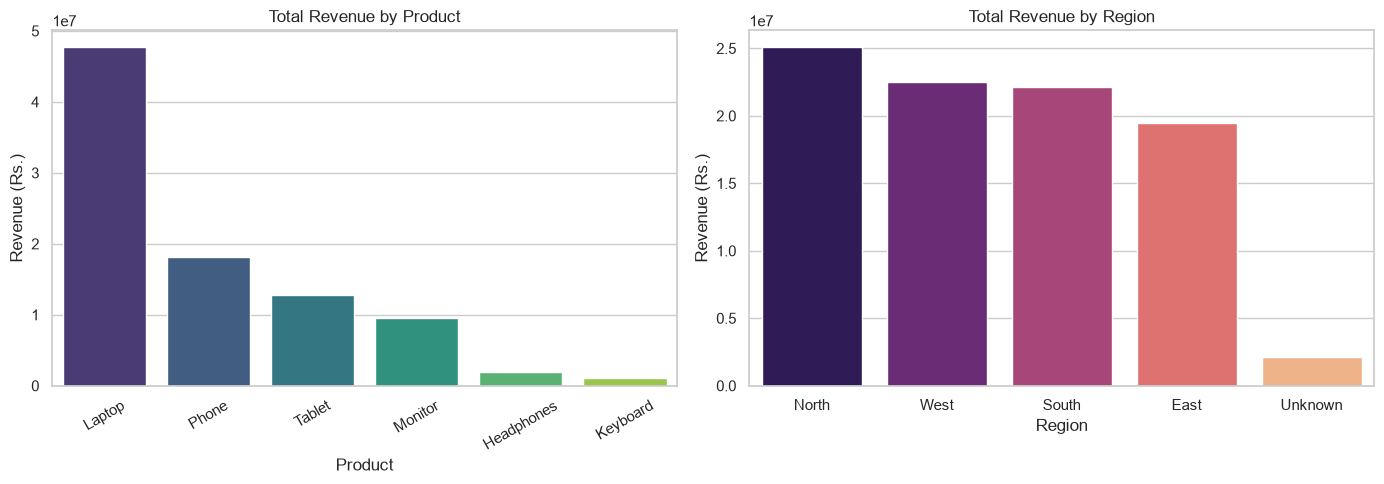

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

prod_rev = df_clean.groupby("Product")["Revenue"].sum().sort_values(ascending=False)
sns.barplot(x=prod_rev.index, y=prod_rev.values, ax=axes[0], palette="viridis", hue=prod_rev.index, legend=False)
axes[0].set_title("Total Revenue by Product")
axes[0].set_ylabel("Revenue (Rs.)")
axes[0].tick_params(axis="x", rotation=30)

reg_rev = df_clean.groupby("Region")["Revenue"].sum().sort_values(ascending=False)
sns.barplot(x=reg_rev.index, y=reg_rev.values, ax=axes[1], palette="magma", hue=reg_rev.index, legend=False)
axes[1].set_title("Total Revenue by Region")
axes[1].set_ylabel("Revenue (Rs.)")

plt.tight_layout()
plt.show()

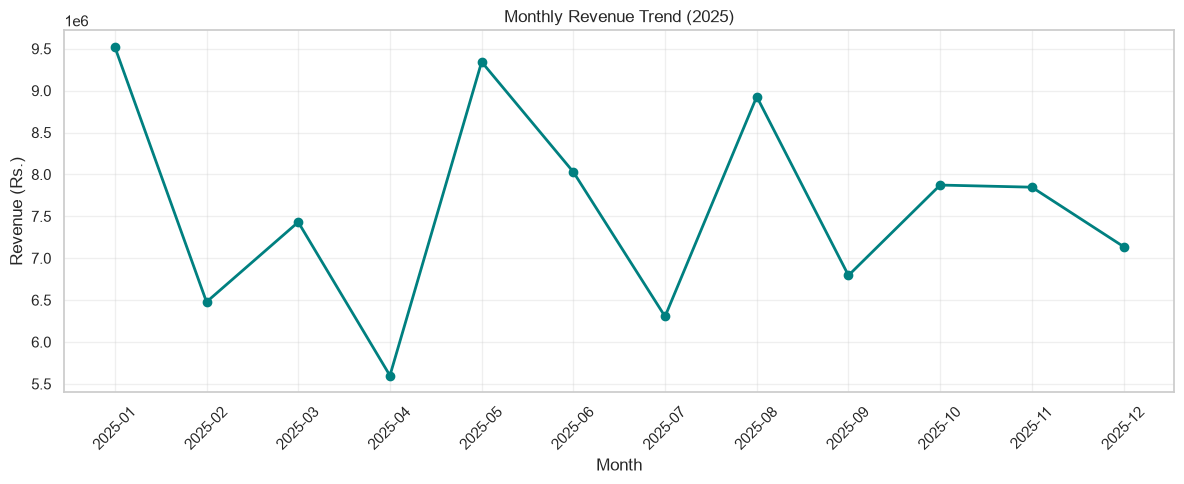

In [19]:
plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, marker="o", color="teal", linewidth=2)
plt.title("Monthly Revenue Trend (2025)")
plt.xlabel("Month")
plt.ylabel("Revenue (Rs.)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

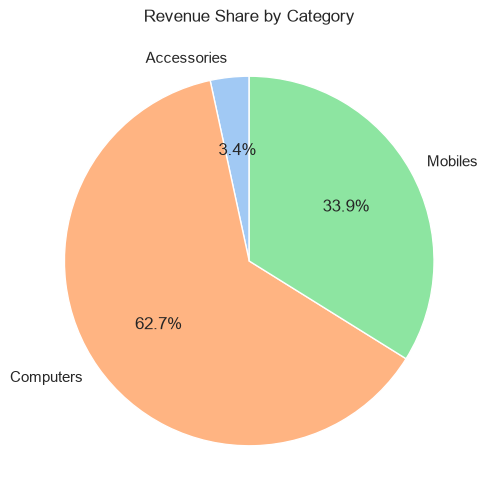

In [20]:
cat_rev = df_clean.groupby("Category")["Revenue"].sum()

plt.figure(figsize=(6, 6))
plt.pie(cat_rev.values, labels=cat_rev.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("pastel"))
plt.title("Revenue Share by Category")
plt.show()

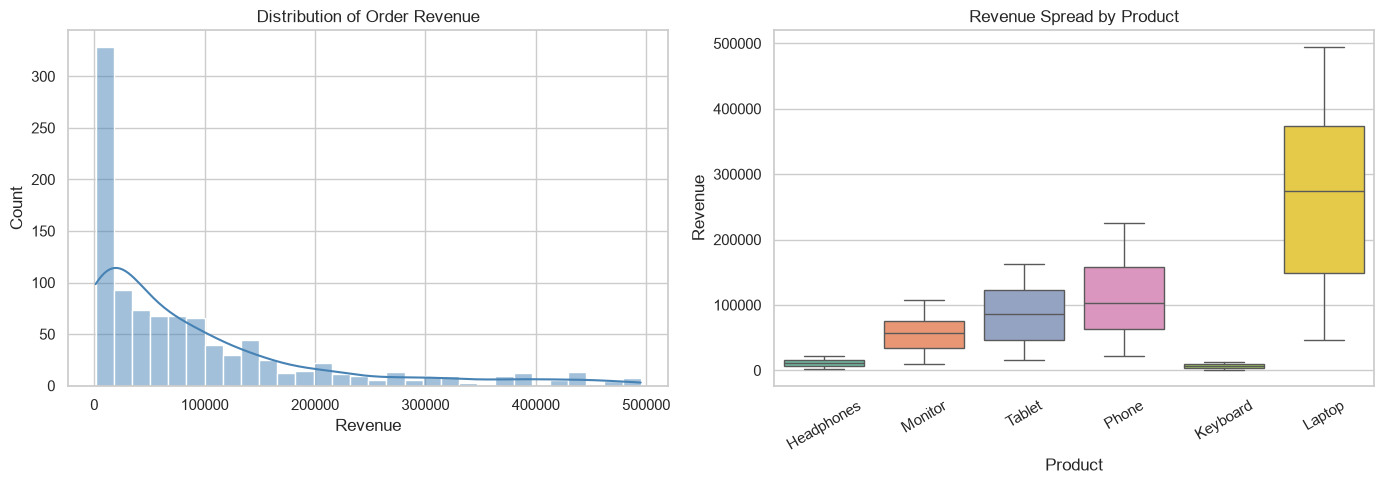

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean["Revenue"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Order Revenue")

sns.boxplot(data=df_clean, x="Product", y="Revenue", ax=axes[1], hue="Product", palette="Set2", legend=False)
axes[1].set_title("Revenue Spread by Product")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

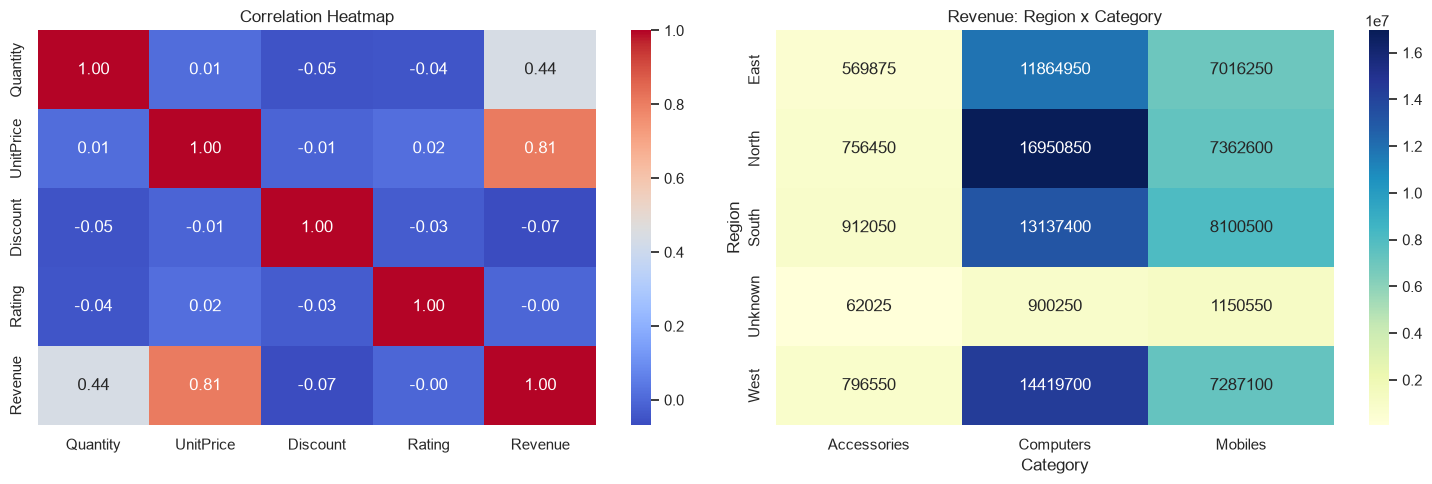

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

corr = df_clean[["Quantity", "UnitPrice", "Discount", "Rating", "Revenue"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[0])
axes[0].set_title("Correlation Heatmap")

pivot = pd.pivot_table(df_clean, values="Revenue", index="Region", columns="Category", aggfunc="sum")
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[1])
axes[1].set_title("Revenue: Region x Category")

plt.tight_layout()
plt.show()

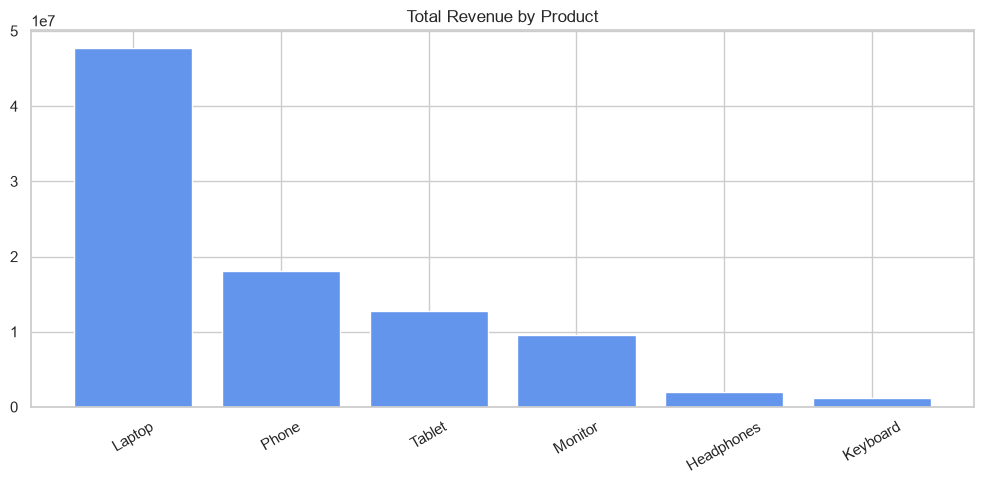

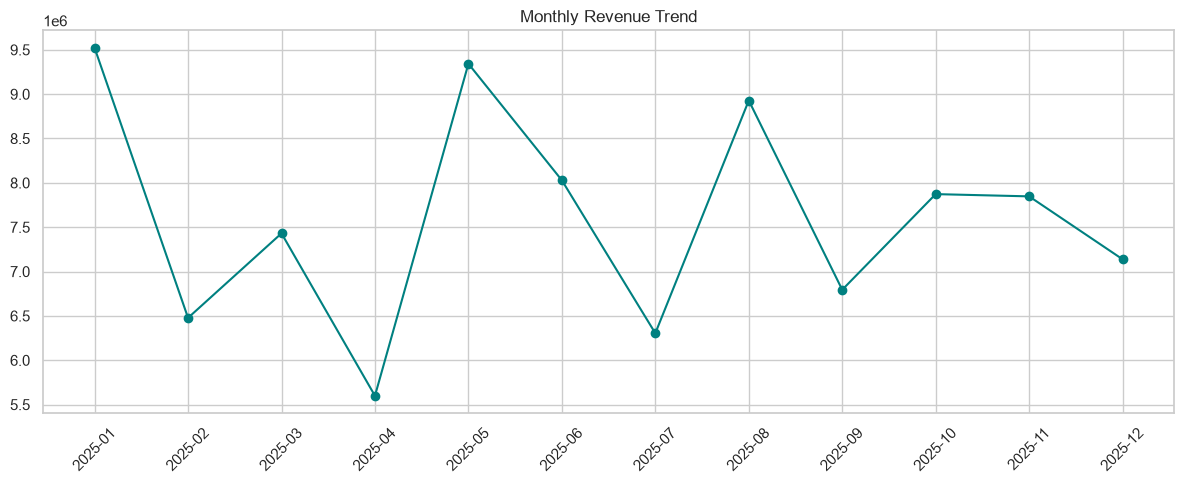

Charts saved in the 'charts' folder: ['monthly_trend.png', 'revenue_by_product.png']


In [23]:
os.makedirs("charts", exist_ok=True)

plt.figure(figsize=(10, 5))
plt.bar(prod_rev.index, prod_rev.values, color="cornflowerblue")
plt.title("Total Revenue by Product")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("charts/revenue_by_product.png", dpi=150)
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, marker="o", color="teal")
plt.title("Monthly Revenue Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("charts/monthly_trend.png", dpi=150)
plt.show()

print("Charts saved in the 'charts' folder:", os.listdir("charts"))

## 8. Reusable workflow and automated report

In [24]:
def clean_sales_data(path):
    """Load a sales CSV and apply every cleaning step from section 3."""
    d = pd.read_csv(path)
    d["Region"] = d["Region"].str.strip().str.title()
    d["Date"] = pd.to_datetime(d["Date"])
    d = d.drop_duplicates()
    d.loc[d["Quantity"] < 0, "Quantity"] = np.nan
    d["Quantity"] = d["Quantity"].fillna(d["Quantity"].median()).astype(int)
    d["Rating"] = d["Rating"].fillna(d["Rating"].median()).astype(int)
    d["Region"] = d["Region"].fillna("Unknown")
    d["Revenue"] = d["Quantity"] * d["UnitPrice"] * (1 - d["Discount"] / 100)
    d["Month"] = d["Date"].dt.to_period("M").astype(str)
    return d

# Check: the function should give exactly the same result as our step-by-step cleaning
check = clean_sales_data("sales_data.csv")
print("Shape:", check.shape)
print("Matches earlier cleaning:", np.isclose(check["Revenue"].sum(), df_clean["Revenue"].sum()))

Shape: (1000, 11)
Matches earlier cleaning: True


In [25]:
def generate_report(d, filename="sales_report.txt"):
    """Build a text report from a cleaned DataFrame, save it, and return it."""
    monthly = d.groupby("Month")["Revenue"].sum()
    by_product = d.groupby("Product")["Revenue"].sum().sort_values(ascending=False)
    by_category = d.groupby("Category")["Revenue"].sum().sort_values(ascending=False)
    by_region = (d[d["Region"] != "Unknown"].groupby("Region")["Revenue"]
                 .sum().sort_values(ascending=False))

    lines = []
    lines.append("=" * 55)
    lines.append("SALES ANALYSIS REPORT")
    lines.append("Generated on: " + pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"))
    lines.append("=" * 55)
    lines.append("")
    lines.append("OVERVIEW")
    lines.append(f"  Orders analysed:    {len(d)}")
    lines.append(f"  Period covered:     {d['Date'].min().date()} to {d['Date'].max().date()}")
    lines.append(f"  Total revenue:      Rs.{d['Revenue'].sum():,.0f}")
    lines.append(f"  Average order:      Rs.{d['Revenue'].mean():,.0f}")
    lines.append(f"  Median order:       Rs.{d['Revenue'].median():,.0f}")
    lines.append(f"  Average rating:     {d['Rating'].mean():.2f} / 5")
    lines.append("")
    lines.append("TOP PERFORMERS")
    lines.append(f"  Best product:   {by_product.index[0]} (Rs.{by_product.iloc[0]:,.0f})")
    lines.append(f"  Best category:  {by_category.index[0]} (Rs.{by_category.iloc[0]:,.0f})")
    lines.append(f"  Best region:    {by_region.index[0]} (Rs.{by_region.iloc[0]:,.0f})")
    lines.append(f"  Best month:     {monthly.idxmax()} (Rs.{monthly.max():,.0f})")
    lines.append(f"  Weakest month:  {monthly.idxmin()} (Rs.{monthly.min():,.0f})")
    lines.append("")
    lines.append("REVENUE BY PRODUCT")
    for name, value in by_product.items():
        lines.append(f"  {name:<12} Rs.{value:>12,.0f}   ({value / by_product.sum() * 100:.1f}%)")
    lines.append("")
    lines.append("DATA QUALITY NOTE")
    lines.append(f"  Orders with unknown region: {(d['Region'] == 'Unknown').sum()}")

    report = "\n".join(lines)
    with open(filename, "w", encoding="utf-8") as f:
        f.write(report)
    return report

In [26]:
report_text = generate_report(check)
print(report_text)
print("\nReport also saved to sales_report.txt")

SALES ANALYSIS REPORT
Generated on: 2026-10-04 03:15

OVERVIEW
  Orders analysed:    1000
  Period covered:     2025-01-01 to 2025-12-31
  Total revenue:      Rs.91,287,100
  Average order:      Rs.91,287
  Median order:       Rs.51,300
  Average rating:     3.04 / 5

TOP PERFORMERS
  Best product:   Laptop (Rs.47,676,750)
  Best category:  Computers (Rs.57,273,150)
  Best region:    North (Rs.25,069,900)
  Best month:     2025-01 (Rs.9,521,725)
  Weakest month:  2025-04 (Rs.5,599,275)

REVENUE BY PRODUCT
  Laptop       Rs.  47,676,750   (52.2%)
  Phone        Rs.  18,132,500   (19.9%)
  Tablet       Rs.  12,784,500   (14.0%)
  Monitor      Rs.   9,596,400   (10.5%)
  Headphones   Rs.   1,979,375   (2.2%)
  Keyboard     Rs.   1,117,575   (1.2%)

DATA QUALITY NOTE
  Orders with unknown region: 25

Report also saved to sales_report.txt


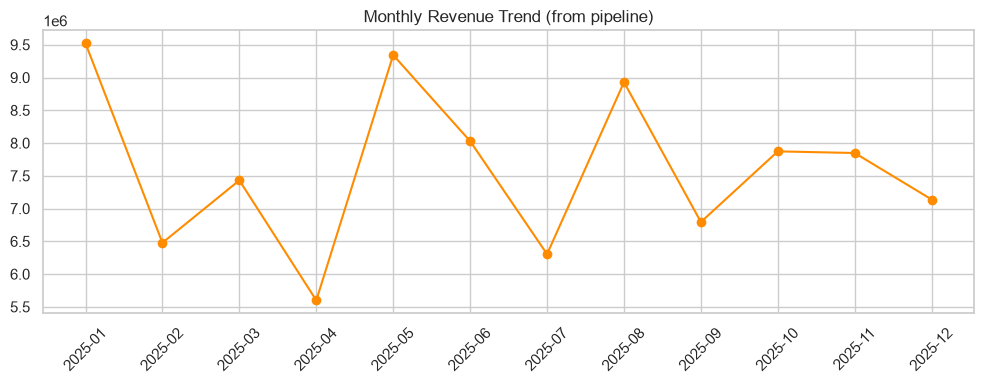

Pipeline finished for 'sales_data.csv': 1000 clean rows.
Files created: pipeline_cleaned.csv, pipeline_report.txt, pipeline_trend.png


In [27]:
def run_pipeline(input_csv, output_prefix="pipeline"):
    """Clean -> save cleaned data -> write report -> save trend chart."""
    d = clean_sales_data(input_csv)
    d.to_csv(f"{output_prefix}_cleaned.csv", index=False)
    generate_report(d, f"{output_prefix}_report.txt")

    m = d.groupby("Month")["Revenue"].sum()
    plt.figure(figsize=(10, 4))
    plt.plot(m.index, m.values, marker="o", color="darkorange")
    plt.title("Monthly Revenue Trend (from pipeline)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(f"{output_prefix}_trend.png", dpi=150)
    plt.show()

    print(f"Pipeline finished for '{input_csv}': {len(d)} clean rows.")
    print(f"Files created: {output_prefix}_cleaned.csv, {output_prefix}_report.txt, {output_prefix}_trend.png")
    return d

final_df = run_pipeline("sales_data.csv")

## 9. Key findings and recommendations

**Findings**
- Total revenue was Rs.91,287,100 across 1000 orders from 2025-01-01 to 2025-12-31, with an average order value of Rs.91,287 and an average customer rating of 3.04 out of 5.
- Laptop was the top product, bringing in Rs.47,676,750 (52.2% of all revenue). Computers was the top category, and North was the top region (Rs.25,069,900).
- Revenue peaked in 2025-01 (Rs.9,521,725) and was lowest in 2025-04 (Rs.5,599,275).
- The median order (Rs.51,300) is well below the average order (Rs.91,287). This means a small number of high-value orders, mostly Laptops, pull the average up.
- Data quality: 15 duplicate rows were removed, missing values in Quantity, Rating and Region were filled, 5 impossible negative quantities were corrected, and inconsistent region labels were standardised.

**Recommendations**
- Keep Laptops well stocked and promoted, since they generate over half of all revenue. Also look at growing Phones and Tablets, so revenue depends less on one product.
- Investigate why 2025-04 was the weakest month and plan promotions or offers for it.
- Study what made 2025-01 so strong and try to repeat it in other months.
- Capture the region on every order, because 25 orders had an unknown region.
- Work on the low average rating (3.04 out of 5) by collecting customer feedback and improving service.

**Workflow:** `run_pipeline("file.csv")` cleans any similar dataset and generates the report and chart automatically.